In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

BASE      = '/content/drive/MyDrive/FraudDetection'
DATA_PATH = os.path.join(BASE, 'data')
PROC_PATH = os.path.join(BASE, 'data', 'processed')
MOD_PATH  = os.path.join(BASE, 'models')

print('Ready!')

Mounted at /content/drive
Ready!


In [ ]:
import numpy as np
import pandas as pd
import pickle
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score
)
warnings.filterwarnings('ignore')

# Load preprocessed data saved by Notebook 2
X_train = np.load(os.path.join(PROC_PATH, 'X_train.npy'))
X_test  = np.load(os.path.join(PROC_PATH, 'X_test.npy'))
y_train = np.load(os.path.join(PROC_PATH, 'y_train.npy'))
y_test  = np.load(os.path.join(PROC_PATH, 'y_test.npy'))

print(f'X_train: {X_train.shape}')
print(f'X_test:  {X_test.shape}')
print(f'Train fraud: {int(y_train.sum()):,}')
print(f'Test fraud:  {int(y_test.sum())}')
print(f'Test fraud rate: {y_test.mean()*100:.4f}%')
print()

# Critical check before training
if y_test.mean() < 0.005:
    print('Test set correct — safe to train models')
else:
    print('WARNING: Test set fraud rate too high')
    print('Fix Notebook 2 before continuing')

X_train: (454902, 30)
X_test:  (56962, 30)
Train fraud: 227,451
Test fraud:  98
Test fraud rate: 0.1720%

Test set correct — safe to train models


In [ ]:
# Helper functions used by all 4 models
# Define once here to avoid repeating code

def show_results(name, y_true, y_pred, y_prob):
    """Print full performance report for one model"""
    print(f'\n{"="*55}')
    print(f'  {name}')
    print(f'{"="*55}')
    # Shows precision recall F1 for each class separately
    print(classification_report(y_true, y_pred,
          target_names=['Legitimate', 'Fraud']))
    # ROC-AUC: 1.0=perfect, 0.5=random guessing
    print(f'  ROC-AUC: {roc_auc_score(y_true, y_prob):.4f}')
    # PR-AUC: better metric than ROC-AUC for imbalanced data
    print(f'  PR-AUC:  {average_precision_score(y_true, y_prob):.4f}')

def plot_cm(y_true, y_pred, title, cmap, filename):
    """Draw and save confusion matrix chart"""
    # confusion_matrix returns 2x2 grid:
    # [[True Negatives,  False Positives],
    #  [False Negatives, True Positives]]
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
        xticklabels=['Legit', 'Fraud'],
        yticklabels=['Legit', 'Fraud'])
    plt.title(f'{title} — Confusion Matrix', fontweight='bold')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.savefig(os.path.join(DATA_PATH, filename), dpi=150)
    plt.show()

print('Helper functions ready!')

Helper functions ready!


Logistic regression

Training Logistic Regression...

  LOGISTIC REGRESSION
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962

  ROC-AUC: 0.9699
  PR-AUC:  0.7237


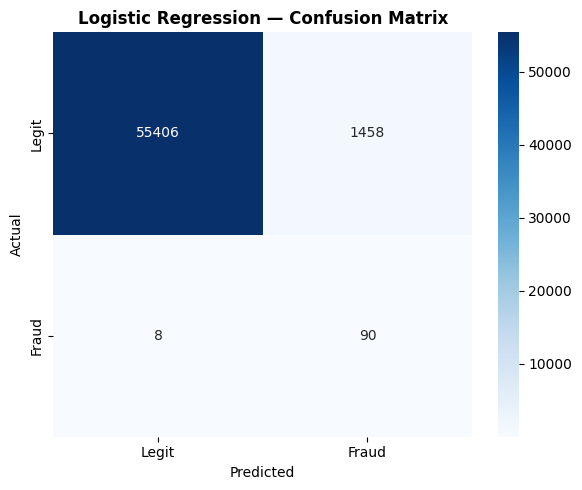

Saved: logistic_regression.pkl


In [ ]:
from sklearn.linear_model import LogisticRegression

# Logistic Regression is the simplest model
# It finds a straight line to separate fraud from legitimate
# Used as a BASELINE — if complex models cannot beat this
# they are not worth the extra complexity

print('Training Logistic Regression...')

lr = LogisticRegression(
    max_iter=1000,    # try up to 1000 steps to find best weights
    C=0.1,            # regularisation — lower = simpler model
    solver='lbfgs',   # mathematical method to find best weights
    random_state=42   # same result every time
)

# .fit() is where learning happens
# Model looks at all training rows and adjusts its weights
lr.fit(X_train, y_train)

# .predict() gives 0 or 1 labels
y_pred_lr = lr.predict(X_test)

# .predict_proba() gives fraud probability between 0 and 1
# [:,1] takes only the fraud probability column
y_prob_lr = lr.predict_proba(X_test)[:, 1]

show_results('LOGISTIC REGRESSION', y_test, y_pred_lr, y_prob_lr)
plot_cm(y_test, y_pred_lr, 'Logistic Regression', 'Blues', 'cm_lr.png')

with open(os.path.join(MOD_PATH, 'logistic_regression.pkl'), 'wb') as f:
    pickle.dump(lr, f)
print('Saved: logistic_regression.pkl')

Random Forest

Training Random Forest... (takes ~5 minutes)

  RANDOM FOREST
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.67      0.85      0.75        98

    accuracy                           1.00     56962
   macro avg       0.84      0.92      0.88     56962
weighted avg       1.00      1.00      1.00     56962

  ROC-AUC: 0.9827
  PR-AUC:  0.8351


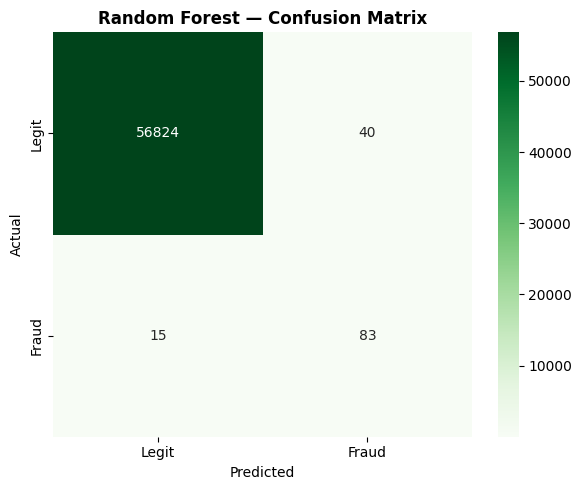

Saved: random_forest.pkl


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest builds many decision trees independently
# Each tree asks yes/no questions about features
# All trees vote and majority decision wins
# Many trees together reduce errors compared to one tree

print('Training Random Forest... (takes ~5 minutes)')

rf = RandomForestClassifier(
    n_estimators=100,      # build 100 independent trees
    max_depth=15,          # each tree can ask max 15 questions
    min_samples_split=5,   # branch needs 5 examples to split
    min_samples_leaf=2,    # end node needs at least 2 examples
    random_state=42,
    n_jobs=-1              # use all CPU cores for speed
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

show_results('RANDOM FOREST', y_test, y_pred_rf, y_prob_rf)
plot_cm(y_test, y_pred_rf, 'Random Forest', 'Greens', 'cm_rf.png')

with open(os.path.join(MOD_PATH, 'random_forest.pkl'), 'wb') as f:
    pickle.dump(rf, f)
print('Saved: random_forest.pkl')

XGBoost

Training XGBoost...
[0]	validation_0-logloss:0.64957
[50]	validation_0-logloss:0.08413
[100]	validation_0-logloss:0.03860
[150]	validation_0-logloss:0.02340
[199]	validation_0-logloss:0.01497

  XGBOOST
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.38      0.90      0.53        98

    accuracy                           1.00     56962
   macro avg       0.69      0.95      0.77     56962
weighted avg       1.00      1.00      1.00     56962

  ROC-AUC: 0.9769
  PR-AUC:  0.8557


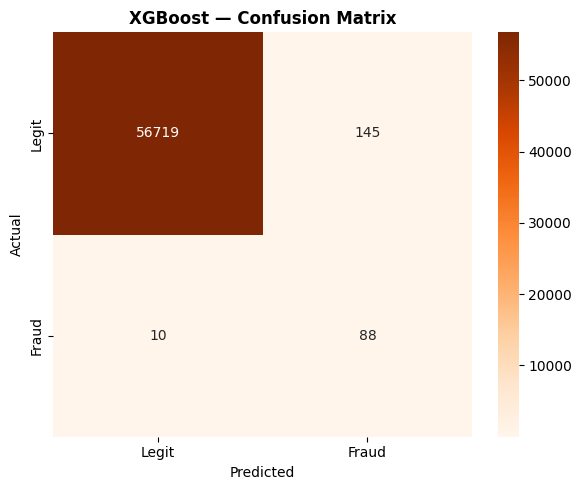

Saved: xgboost.pkl


In [ ]:
from xgboost import XGBClassifier

# XGBoost builds trees SEQUENTIALLY
# Each new tree fixes the mistakes of all previous trees
# This boosting approach makes it very powerful

print('Training XGBoost...')

xgb = XGBClassifier(
    n_estimators=200,      # build 200 sequential trees
    learning_rate=0.05,    # each tree contributes only 5%
    max_depth=6,           # shallower trees than RF
    subsample=0.8,         # each tree sees 80% of rows randomly
    colsample_bytree=0.8,  # each tree sees 80% of features randomly
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# eval_set monitors test performance during training
# verbose=50 prints progress every 50 trees
xgb.fit(X_train, y_train,
        eval_set=[(X_test, y_test)],
        verbose=50)

y_pred_xgb = xgb.predict(X_test)
y_prob_xgb = xgb.predict_proba(X_test)[:, 1]

show_results('XGBOOST', y_test, y_pred_xgb, y_prob_xgb)
plot_cm(y_test, y_pred_xgb, 'XGBoost', 'Oranges', 'cm_xgb.png')

with open(os.path.join(MOD_PATH, 'xgboost.pkl'), 'wb') as f:
    pickle.dump(xgb, f)
print('Saved: xgboost.pkl')

Neural Network

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print('Training Neural Network... (takes ~10 minutes)')
tf.random.set_seed(42)

# Build network layer by layer
# Data flows through each layer from top to bottom
model = Sequential([
    # Layer 1: 128 neurons, ReLU activation
    # input_shape tells it we have 30 features
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    BatchNormalization(),  # stabilise layer outputs
    Dropout(0.3),          # switch off 30% of neurons randomly

    # Layer 2: 64 neurons
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    # Layer 3: 32 neurons
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    # Layer 4: 16 neurons
    Dense(16, activation='relu'),

    # Output: 1 neuron, sigmoid outputs fraud probability 0-1
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)
model.summary()

callbacks = [
    # Stop if val_loss does not improve for 8 epochs
    EarlyStopping(monitor='val_loss', patience=8,
                  restore_best_weights=True),
    # Reduce learning rate if training stalls for 4 epochs
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=4, min_lr=1e-6)
]

history = model.fit(
    X_train, y_train,
    epochs=60,
    batch_size=512,
    validation_split=0.15,
    callbacks=callbacks,
    verbose=1
)

Training Neural Network... (takes ~10 minutes)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,745 (61.50 KB)

 Trainable params: 15,297 (59.75 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/60
756/756 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - accuracy: 0.9731 - auc: 0.9966 - loss: 0.0710 - val_accuracy: 0.9992 - val_auc: 0.0000e+00 - val_loss: 0.0102 - learning_rate: 0.0010
Epoch 2/60
756/756 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9931 - auc: 0.9994 - loss: 0.0205 - val_accuracy: 1.0000 - val_auc: 0.0000e+00 - val_loss: 0.0022 - learning_rate: 0.0010
Epoch 3/60
756/756 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9960 - auc: 0.9996 - loss: 0.0131 - val_accuracy: 1.0000 - val_auc: 0.0000e+00 - val_loss: 0.0013 - learning_rate: 0.0010
Epoch 4/60
756/756 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9973 - auc: 0.9997 - loss: 0.0097 - val_accuracy: 1.0000 - val_auc: 0.0000e+00 - val_loss: 9.4902e-04 - learning_rate: 0.0010
Epoch 5/60
756/756 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9977 - auc: 0.9997 - loss: 0.0082 - val_accuracy: 1.0000 - val_auc: 0.0000e+00 - val_loss: 6.4411e-04 - learning_rate: 0.0010
Epoch 6/60
756/756 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/s

Evaluate Neural Network

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step

  NEURAL NETWORK
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.81      0.84      0.82        98

    accuracy                           1.00     56962
   macro avg       0.91      0.92      0.91     56962
weighted avg       1.00      1.00      1.00     56962

  ROC-AUC: 0.9706
  PR-AUC:  0.8559


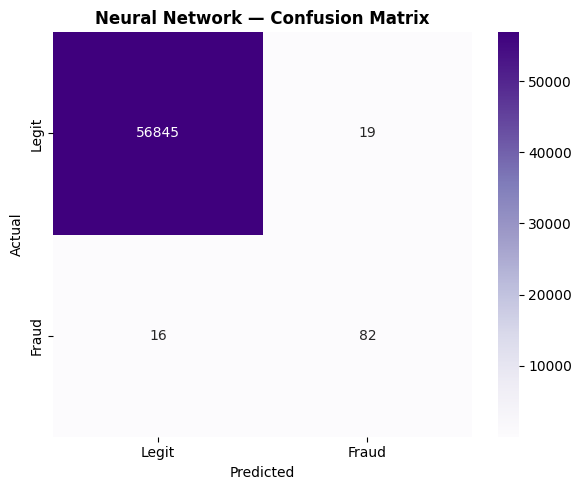

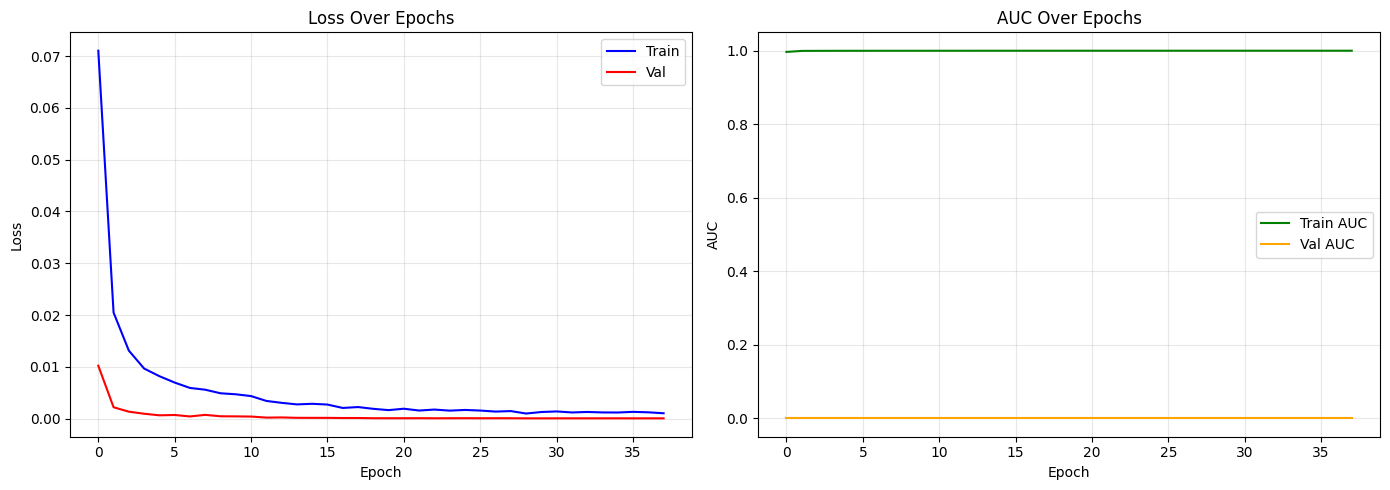

Saved: neural_network.h5

All 4 models saved!
Files: ['logistic_regression.pkl', 'random_forest.pkl', 'xgboost.pkl', 'neural_network.h5', 'best_threshold.pkl', 'shap_explainer.pkl', 'shap_background.npy', 'feature_names.pkl', 'scaler_amount.pkl', 'scaler_time.pkl']


In [ ]:
# Get predictions from neural network
# .flatten() converts 2D output to 1D array
y_prob_nn = model.predict(X_test).flatten()

# Convert probabilities to 0/1 using threshold 0.5
y_pred_nn = (y_prob_nn >= 0.5).astype(int)

show_results('NEURAL NETWORK', y_test, y_pred_nn, y_prob_nn)
plot_cm(y_test, y_pred_nn, 'Neural Network', 'Purples', 'cm_nn.png')

# Training history charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss chart — both lines should go down and converge
axes[0].plot(history.history['loss'],     label='Train', color='blue')
axes[0].plot(history.history['val_loss'], label='Val',   color='red')
axes[0].set_title('Loss Over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# AUC chart — both lines should go up and converge
axes[1].plot(history.history['auc'],     label='Train AUC', color='green')
axes[1].plot(history.history['val_auc'], label='Val AUC',   color='orange')
axes[1].set_title('AUC Over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUC')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(DATA_PATH, 'nn_training.png'), dpi=150)
plt.show()

# Save in .h5 format — cannot use pickle for neural networks
model.save(os.path.join(MOD_PATH, 'neural_network.h5'))
print('Saved: neural_network.h5')
print()
print('All 4 models saved!')
print('Files:', os.listdir(MOD_PATH))